In [1]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

# Initialize Aer simulator backend
simulator = AerSimulator()
SHOTS = 100

print("Libraries imported successfully!")

Libraries imported successfully!


# Challenge 1: Predict the Output
**Name:** POLAMARASETTY JAGADEESH
**Event:** Qiskit Fall Fest 2026 - Vishnu Institute of Technology  

## Part 1: Theoretical Predictions ("Think Before You Run")

All circuits start with the qubit in state $\vert{}0\rangle$:

1. **Circuit A (One X gate):**
   - The $X$ gate is a bit-flip (quantum NOT) gate.
   - It rotates $\vert{}0\rangle \rightarrow \vert{}1\rangle$.
   - **Prediction:** 100% chance of measuring `1`. Expected counts over 100 shots: `{'1': 100}`.

2. **Circuit B (Two X gates):**
   - The first $X$ gate maps $\vert{}0\rangle \rightarrow \vert{}1\rangle$.
   - The second $X$ gate maps $\vert{}1\rangle \rightarrow \vert{}0\rangle$ ($X \cdot X = I$, identity operation).
   - **Prediction:** 100% chance of measuring `0`. Expected counts over 100 shots: `{'0': 100}`.

3. **Circuit C (One H gate):**
   - The Hadamard ($H$) gate places $\vert{}0\rangle$ into equal superposition: $\vert{}+\rangle = \frac{1}{\sqrt{2}}(\vert{}0\rangle + \vert{}1\rangle)$.
   - **Prediction:** Equal probability (50% each) of measuring `0` or `1`. Expected counts over 100 shots: roughly 50 each (e.g., ~50 `0`s, ~50 `1`s).
   - **Will Circuit C always produce the same measurement result?** No. Quantum measurement randomly collapses the superposition state upon measurement.

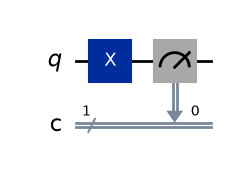

Circuit A Measurement Results: {'1': 100}


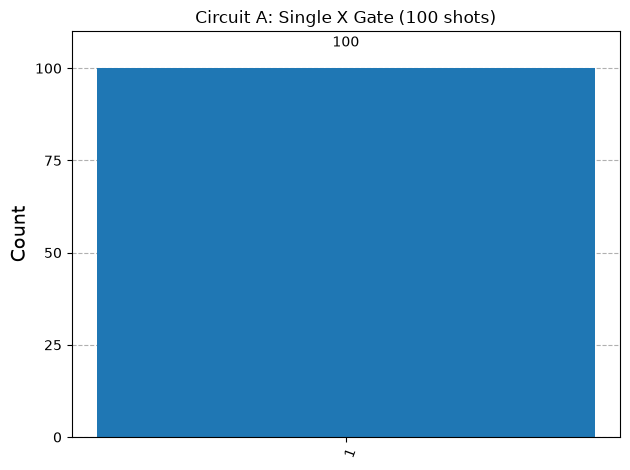

In [2]:
# 1. Create a 1-qubit, 1-classical-bit circuit
qc_a = QuantumCircuit(1, 1)

# 2. Apply single X gate
qc_a.x(0)

# 3. Add measurement
qc_a.measure(0, 0)

# 4. Draw the circuit
display(qc_a.draw('mpl'))

# 5. Run simulation for 100 shots
job_a = simulator.run(qc_a, shots=SHOTS)
counts_a = job_a.result().get_counts()
print("Circuit A Measurement Results:", counts_a)

# 6. Plot histogram
plot_histogram(counts_a, title="Circuit A: Single X Gate (100 shots)")

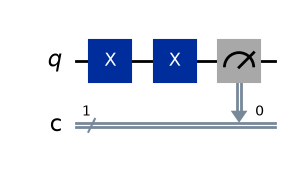

Circuit B Measurement Results: {'0': 100}


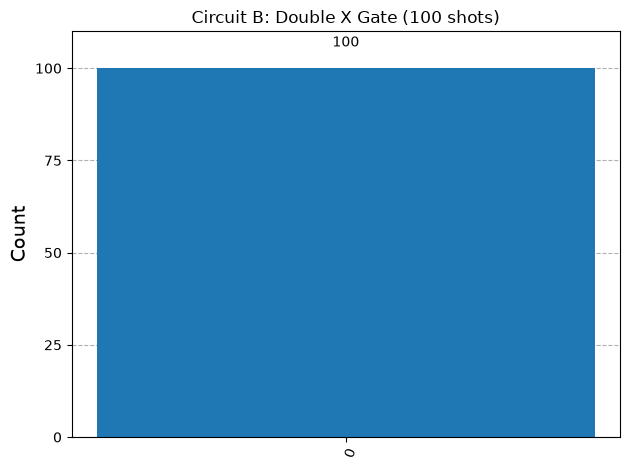

In [3]:
# 1. Create circuit
qc_b = QuantumCircuit(1, 1)

# 2. Apply two consecutive X gates
qc_b.x(0)
qc_b.x(0)

# 3. Add measurement
qc_b.measure(0, 0)

# 4. Draw the circuit
display(qc_b.draw('mpl'))

# 5. Run simulation for 100 shots
job_b = simulator.run(qc_b, shots=SHOTS)
counts_b = job_b.result().get_counts()
print("Circuit B Measurement Results:", counts_b)

# 6. Plot histogram
plot_histogram(counts_b, title="Circuit B: Double X Gate (100 shots)")

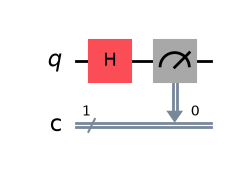

Circuit C Measurement Results: {'1': 54, '0': 46}


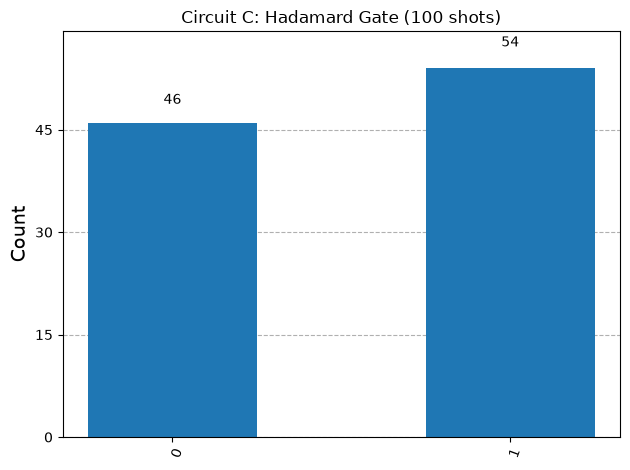

In [4]:
# 1. Create circuit
qc_c = QuantumCircuit(1, 1)

# 2. Apply single H (Hadamard) gate
qc_c.h(0)

# 3. Add measurement
qc_c.measure(0, 0)

# 4. Draw the circuit
display(qc_c.draw('mpl'))

# 5. Run simulation for 100 shots
job_c = simulator.run(qc_c, shots=SHOTS)
counts_c = job_c.result().get_counts()
print("Circuit C Measurement Results:", counts_c)

# 6. Plot histogram
plot_histogram(counts_c, title="Circuit C: Hadamard Gate (100 shots)")

## Part 2: Comparison & Observations

| Circuit | Gate(s) Applied | Theoretical Prediction | Experimental Result (100 shots) | Analysis |
| :--- | :--- | :--- | :--- | :--- |
| **Circuit A** | $X$ | 100% `1` (`{'1': 100}`) | `{'1': 100}` | **Exact Match.** The bit-flip gate deterministically maps $\vert{}0\rangle \rightarrow \vert{}1\rangle$. |
| **Circuit B** | $X$, $X$ | 100% `0` (`{'0': 100}`) | `{'0': 100}` | **Exact Match.** Two consecutive $X$ gates act as the identity operator ($X^2 = I$), restoring the initial $\vert{}0\rangle$ state. |
| **Circuit C** | $H$ | 50% `0`, 50% `1` | Distributed near 50/50 | **Consistent.** True superposition causes probabilistic measurement collapse. Minor divergence from an exact 50/50 split is expected due to statistical shot noise across 100 shots. |